In [28]:
import pandas as pd
df = pd.read_excel("malaria_kenya.xlsx")   # use pd.read_csv if it's a .csv
print(df.shape)
print(df.columns.tolist())
df.info()
df.head()


(6110, 22)
['county', 'year', 'month', 'date', 'temperature', 'precipitation', 'NDVI', 'ITN_coverage', 'elevation', 'population_density', 'incidence_per_1000', 'transmission_state', 'temperature_lag1', 'temperature_lag2', 'precipitation_lag1', 'precipitation_lag2', 'NDVI_lag1', 'NDVI_lag2', 'ITN_coverage_lag1', 'ITN_coverage_lag2', 'transmission_state_lag1', 'transmission_state_lag2']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6110 entries, 0 to 6109
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   county                   6110 non-null   object        
 1   year                     6110 non-null   int64         
 2   month                    6110 non-null   int64         
 3   date                     6110 non-null   datetime64[ns]
 4   temperature              6110 non-null   float64       
 5   precipitation            6110 non-null   float64       
 6   NDVI        

,county,year,month,date,temperature,precipitation,NDVI,ITN_coverage,elevation,population_density,...,temperature_lag1,temperature_lag2,precipitation_lag1,precipitation_lag2,NDVI_lag1,NDVI_lag2,ITN_coverage_lag1,ITN_coverage_lag2,transmission_state_lag1,transmission_state_lag2
0,Mombasa,2015,3,2015-03-01,25.972892,108.013750,0.552837,0.359693,1123.620357,2609.938745,...,29.520526,29.709979,50.567755,17.139781,0.458672,0.406952,0.310766,0.300482,1,1
1,Mombasa,2015,4,2015-04-01,26.162511,155.489784,0.577394,0.377128,1123.620357,2609.938745,...,25.972892,29.520526,108.013750,50.567755,0.552837,0.458672,0.359693,0.310766,1,1
2,Mombasa,2015,5,2015-05-01,24.598396,177.661835,0.692266,0.366170,1123.620357,2609.938745,...,26.162511,25.972892,155.489784,108.013750,0.577394,0.552837,0.377128,0.359693,1,1
3,Mombasa,2015,6,2015-06-01,23.863852,168.458890,0.690547,0.346752,1123.620357,2609.938745,...,24.598396,26.162511,177.661835,155.489784,0.692266,0.577394,0.366170,0.377128,2,1
4,Mombasa,2015,7,2015-07-01,24.317988,161.110164,0.626902,0.388608,1123.620357,2609.938745,...,23.863852,24.598396,168.458890,177.661835,0.690547,0.692266,0.346752,0.366170,2,2


In [29]:
# 1. Check the time period and number of counties
print("Date range:", df["date"].min(), "to", df["date"].max())
print("Number of counties:", df["county"].nunique())
print("Rows per county:")
display(df["county"].value_counts().describe())

# 2. Check duplicate county-month records
duplicates = df.duplicated(subset=["county", "date"]).sum()
print("Duplicate county-month records:", duplicates)

# 3. Check whether the data are sorted by county and date
sorted_df = df.sort_values(["county", "date"])
print("Already sorted:", df[["county", "date"]].reset_index(drop=True).equals(
    sorted_df[["county", "date"]].reset_index(drop=True)
))

# 4. Inspect important numerical variables
display(
    df[["incidence_per_1000", "temperature",
        "precipitation", "NDVI", "ITN_coverage"]].describe()
)

# 5. Inspect the encoded transmission categories
print("Transmission-state values:")
print(df["transmission_state"].value_counts().sort_index())


Date range: 2015-03-01 00:00:00 to 2025-12-01 00:00:00
Number of counties: 47
Rows per county:


,count
count,47.0
mean,130.0
std,0.0
min,130.0
25%,130.0
50%,130.0
75%,130.0
max,130.0


Duplicate county-month records: 0
Already sorted: False


,incidence_per_1000,temperature,precipitation,NDVI,ITN_coverage
count,6110.000000,6110.000000,6110.000000,6110.000000,6110.000000
mean,11.028890,26.970665,101.195654,0.531245,0.629516
std,5.623588,2.186491,57.978165,0.098267,0.184222
min,1.634830,22.343677,10.000000,0.228533,0.252635
25%,6.822384,24.943499,47.549084,0.455230,0.473572
50%,9.999072,26.934832,99.985778,0.531935,0.627232
75%,14.152424,29.028869,156.060930,0.605851,0.798673
max,51.993444,31.573705,258.635455,0.849641,0.900000


Transmission-state values:
transmission_state
0     679
1    4148
2    1238
3      45
Name: count, dtype: int64


In [30]:
# Sort observations before checking time-series features
check = df.sort_values(["county", "date"]).copy()

# Check monthly continuity
check["month_gap"] = (
    check.groupby("county")["date"].diff()
)

print("Date gaps other than one month:",
      (check["month_gap"].dropna().dt.days != 28).sum())

# Better check: compare each date with the previous date plus one month
expected_previous = (
    check.groupby("county")["date"].shift(1)
    + pd.DateOffset(months=1)
)

print("Missing or irregular monthly transitions:",
      (check["date"].ne(expected_previous) &
       check.groupby("county").cumcount().gt(0)).sum())

# Compare provided lag with the previous observation
check["previous_temperature"] = (
    check.groupby("county")["temperature"].shift(1)
)

check["lag_difference"] = (
    check["temperature_lag1"] - check["previous_temperature"]
)

print("Temperature lag mismatches:",
      check.loc[check.groupby("county").cumcount().gt(0),
                "lag_difference"].abs().gt(1e-6).sum())

Date gaps other than one month: 5734
Missing or irregular monthly transitions: 0
Temperature lag mismatches: 0


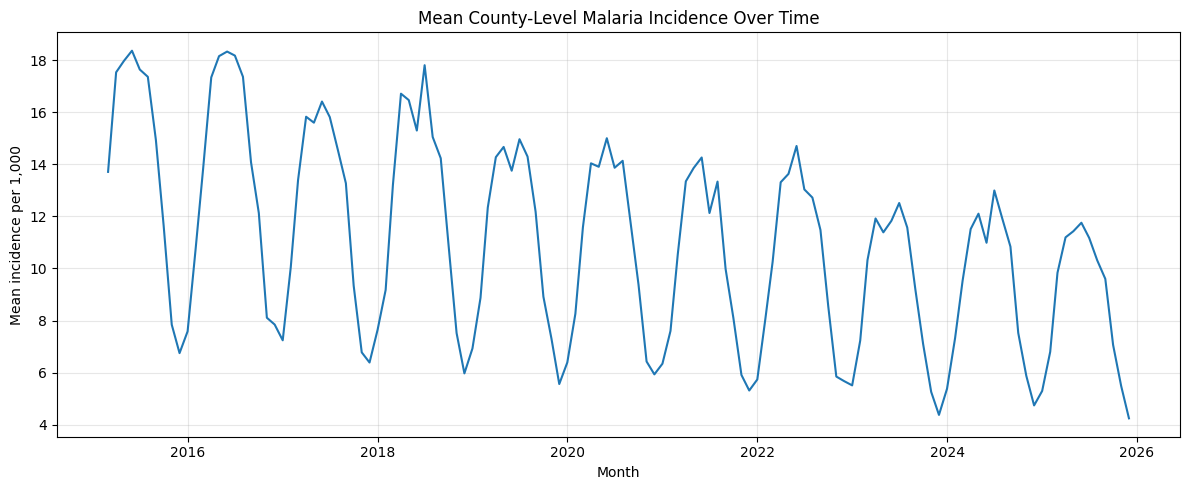

In [31]:
import matplotlib.pyplot as plt

monthly_mean = (
    df.groupby("date")["incidence_per_1000"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(12, 5))
plt.plot(monthly_mean.index, monthly_mean.values)
plt.title("Mean County-Level Malaria Incidence Over Time")
plt.xlabel("Month")
plt.ylabel("Mean incidence per 1,000")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:
# Average incidence by year
yearly_mean = (
    df.groupby("year")["incidence_per_1000"]
    .mean()
    .round(2)
)

print("Mean incidence by year:")
display(yearly_mean)

# Average incidence by calendar month
monthly_seasonality = (
    df.groupby("month")["incidence_per_1000"]
    .mean()
    .round(2)
)

print("Mean incidence by calendar month:")
display(monthly_seasonality)

Mean incidence by year:


,incidence_per_1000
year,
2015,14.37
2016,13.64
2017,12.06
2018,12.50
2019,11.17
2020,10.89
2021,10.06
2022,10.25
2023,9.02


Mean incidence by calendar month:


,incidence_per_1000
month,
1,6.41
2,8.42
3,11.69
4,14.27
5,14.47
6,14.61
7,14.56
8,13.87
9,11.96


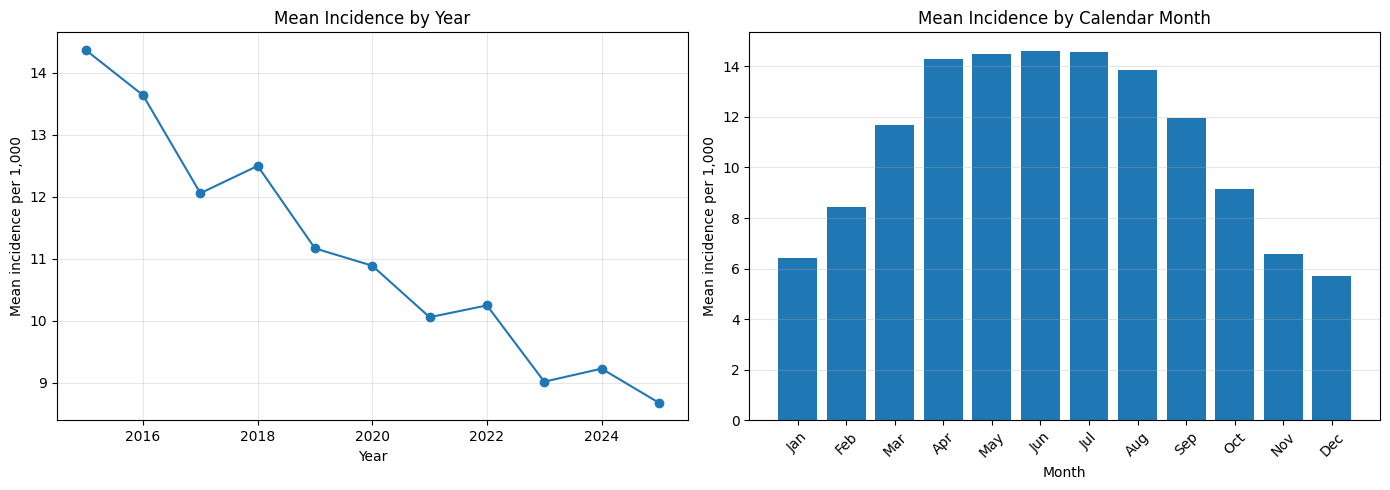

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Annual trend
axes[0].plot(yearly_mean.index, yearly_mean.values, marker="o")
axes[0].set_title("Mean Incidence by Year")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Mean incidence per 1,000")
axes[0].grid(True, alpha=0.3)

# Monthly pattern
month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]
axes[1].bar(month_names, monthly_seasonality.values)
axes[1].set_title("Mean Incidence by Calendar Month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Mean incidence per 1,000")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("malaria_trends.png", dpi=200, bbox_inches="tight")
plt.show()

In [34]:
plt.savefig("malaria_trends.png", dpi=200, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>